# moonshot_compounding — Test 1 (Momentum) — **PHASE B: Baseline**

The actual test. Phase A validated the harness; this runs it. **Baseline = the
honest, untuned, textbook version.** Measured once and frozen as the reference
every later enhancement compares against — tuning before the baseline is set
would contaminate that reference.

**Reads the v3 panel.** B0 hard-stops if pointed at a pre-fix panel.

---

## What is being tested

Does a stock's past-year return predict its next-month return? Rank the PIT
universe into deciles on 12-1 momentum each month, hold equal-weighted for a
month, measure the long-short spread (D10−D1). Everything after B3 interrogates
whether that spread is **real, stable, tradeable, and not a data artifact**.

This is **harness validation** — momentum in Indian equities is well documented,
so a strong positive is *expected* and weak evidence. A **null result is the
informative outcome**: it would more likely indicate a pipeline bug than a
genuine absence of momentum.

## The cells

| Cell | Question |
|---|---|
| B0 | Setup, provenance guard, frozen parameters, run folder |
| B1 | Signal + deciles (leakage self-test first) |
| B2 | Forward returns per decile (+ monotonicity) |
| B3 | Long-short spread + decile profile / cumulative plots |
| B4 | Real or luck? Sharpe + **block-bootstrap CI** |
| B5 | Stable? Year-by-year + rolling Sharpe |
| B6 | 2020 crash (pipeline check — absence is the red flag) |
| B7 | **Tradeable?** Liquidity-tercile decomposition (the trip-wire) |
| B8 | 2018 H2 data-artifact check |
| B9 | Information coefficient (full-cross-section cross-check) |
| B10 | Findings log |

## Settled parameters (frozen)

Rebalance last trading day of month · signal [t-252, t-21] · PIT filter
`== 1` · strict 232/232 less vendor-failure rows · **min 100 names/month** ·
exit = compound observed days · block bootstrap 12-month blocks · **IC included**.

## Limitations carried in

**Gross of transaction costs.** Monthly decile rebalancing has real turnover;
modelling costs is an enhancement (it needs an assumption), not baseline.
**Equal-weighted** overweights small caps, interacting with B7.
`realized_vol_120` is unusable Mar–Sep 2025 (vendor-failure), but momentum does
not use vol.

## B0 — Setup, resolver, provenance guard, run folder

In [5]:
# =============================================================================
# CELL B0 — SETUP, RESOLVER, PROVENANCE GUARD, RUN FOLDER
# =============================================================================
# Phase B is SELF-CONTAINED: it recomputes the momentum signal from the panel
# rather than depending on Phase A's in-memory state, so it can be run on its
# own. The signal logic is byte-for-byte the same as Phase A (same window, same
# vendor-failure adjustment) — a mismatch would mean the leakage proof no longer
# describes what is being tested, so the definitions are duplicated deliberately
# and a self-test below re-confirms the leakage property.
#
# BASELINE DISCIPLINE: this is iteration one — the honest, untuned, textbook
# version. No parameter tuning, no name filtering beyond the spec, no
# optimisation. It is measured once and FROZEN as the reference every later
# enhancement is compared against. Tuning before the baseline is set would
# contaminate that reference.
#
# The frozen panel makes a baseline run fully reproducible: same input, same
# output. Any run-to-run difference comes ONLY from code changes, never data.
# =============================================================================
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.6f}")

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "figure.autolayout": True,
})

# -----------------------------------------------------------------------------
# Drive + resolver
# -----------------------------------------------------------------------------
try:
    from google.colab import drive  # type: ignore
    drive.mount("/content/drive", force_remount=False)
except ImportError:
    pass

BASE = Path("/content/drive/MyDrive/moonshot_compounding")
RUN_DATE = datetime.now().strftime("%Y-%m-%d")
RUN_STAMP = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

if not BASE.exists():
    raise RuntimeError(f"{BASE} not found. Mount Drive (Cell 0) or fix a stale mount.")

def resolve_newest(folder, pattern):
    hits = sorted((BASE / folder).glob(pattern), key=lambda p: p.stat().st_mtime, reverse=True)
    if not hits:
        raise FileNotFoundError(f"No file matching {folder}/{pattern}")
    return hits[0]

PANEL_PATH = resolve_newest("features", "feature_panel_with_pit_v2_*.parquet")
print("=" * 78)
print("PHASE B — MOMENTUM — BASELINE")
print("=" * 78)
print(f"  run stamp : {RUN_STAMP}")
print(f"  panel     : {PANEL_PATH.name}")

# -----------------------------------------------------------------------------
# Run folder — timestamped, never overwritten. Machine artifacts and plots go
# under run_<date>/; the human findings log is written at the momentum/ root
# only when the whole test completes.
# -----------------------------------------------------------------------------
HYP_ROOT = BASE / "hypotheses" / "momentum"
RUN_DIR = HYP_ROOT / f"run_{RUN_DATE}"
ARTIFACT_DIR = RUN_DIR / "artifacts"
PLOT_DIR = RUN_DIR / "plots"
for d in (ARTIFACT_DIR, PLOT_DIR):
    d.mkdir(parents=True, exist_ok=True)
print(f"  run dir   : {RUN_DIR.relative_to(BASE)}")

def save_artifact(df, name):
    """Persist a machine artifact (evidence, regenerable) as CSV."""
    p = ARTIFACT_DIR / f"{name}_{RUN_DATE}.csv"
    df.to_csv(p, index=False)
    print(f"    -> artifact: {p.name}  ({len(df):,} rows)")
    return p

def save_plot(fig, name):
    """Persist a plot next to the artifacts it illustrates."""
    p = PLOT_DIR / f"{name}_{RUN_DATE}.png"
    fig.savefig(p, bbox_inches="tight")
    print(f"    -> plot: {p.name}")
    return p

# -----------------------------------------------------------------------------
# Load panel + detect key columns (same detection discipline as Phase A A0)
# -----------------------------------------------------------------------------
panel = pd.read_parquet(PANEL_PATH)

_tick = [c for c in panel.columns if c.lower() in ("ticker","symbol")]
_date = [c for c in panel.columns if c.lower() in ("date","dt")]
assert len(_tick) == 1 and len(_date) == 1, f"key detection ambiguous: {_tick}, {_date}"
TICKER_COL, DATE_COL = _tick[0], _date[0]
panel[DATE_COL] = pd.to_datetime(panel[DATE_COL])
if getattr(panel[DATE_COL].dtype, "tz", None) is not None:
    panel[DATE_COL] = panel[DATE_COL].dt.tz_localize(None)
panel = panel.sort_values([TICKER_COL, DATE_COL]).reset_index(drop=True)

for c in ["daily_return", "in_nifty500_flag", "turnover", "date_status"]:
    assert c in panel.columns, f"missing required column {c} — is this the v3 panel?"

# -----------------------------------------------------------------------------
# v3 PROVENANCE GUARD — refuse to run on a pre-fix panel.
# Numbers off the old panel would look like results but measure the defect.
# -----------------------------------------------------------------------------
MARKET_CLOSED_REMOVED = [pd.Timestamp(d) for d in
    ["2014-04-24","2014-10-15","2026-01-15","2026-05-01","2026-05-28","2026-06-26"]]
_present = [d for d in MARKET_CLOSED_REMOVED if (panel[DATE_COL] == d).any()]
if _present:
    raise RuntimeError(
        f"Pre-fix panel: market-closed dates present {[str(d.date()) for d in _present]}. "
        "Rebuild v3 before running Phase B.")

VENDOR_FAILURE_DATES = set(pd.Timestamp(d) for d in
                           panel.loc[panel["date_status"] == "vendor_failure", DATE_COL].unique())
print(f"  rows      : {len(panel):,}   dates: {panel[DATE_COL].nunique():,}   "
      f"tickers: {panel[TICKER_COL].nunique():,}")
print(f"  vendor-failure dates: {sorted(str(pd.Timestamp(d).date()) for d in VENDOR_FAILURE_DATES)}")

# -----------------------------------------------------------------------------
# Baseline parameters — FROZEN. Stated here, in one place, before any result.
# -----------------------------------------------------------------------------
LOOKBACK = 252          # signal window start, trading rows back
SKIP = 21               # skip most recent month (short-term reversal)
WINDOW_ROWS = LOOKBACK - SKIP + 1   # 232
N_DECILES = 10
MIN_NAMES_PER_MONTH = 100   # skip a rebalance with fewer eligible names — with
                            # <100, deciles carry <10 names each and are noise
N_TERCILES = 3
BLOCK_LEN = 12          # block-bootstrap block length (months); momentum is
                        # persistent, so a 1-month block would understate the CI
N_BOOTSTRAP = 10_000
SEED = 20260724

print(f"\n  BASELINE PARAMETERS (frozen):")
print(f"    lookback={LOOKBACK} skip={SKIP} window={WINDOW_ROWS} deciles={N_DECILES}")
print(f"    min_names_per_month={MIN_NAMES_PER_MONTH} terciles={N_TERCILES}")
print(f"    bootstrap: block_len={BLOCK_LEN} n={N_BOOTSTRAP:,} seed={SEED}")
print("=" * 78)

Mounted at /content/drive
PHASE B — MOMENTUM — BASELINE
  run stamp : 2026-07-27 05:19:37
  panel     : feature_panel_with_pit_v2_2026-07-24.parquet
  run dir   : hypotheses/momentum/run_2026-07-27
  rows      : 3,328,132   dates: 4,237   tickers: 1,069
  vendor-failure dates: ['2025-03-18']

  BASELINE PARAMETERS (frozen):
    lookback=252 skip=21 window=232 deciles=10
    min_names_per_month=100 terciles=3
    bootstrap: block_len=12 n=10,000 seed=20260724


## B1 — Signal, rebalance calendar, decile assignment

Recomputes the signal (self-contained), builds the monthly calendar from the panel's own trading days, applies `flag == 1`, sorts into deciles. Leakage self-test runs before the full computation.

In [6]:
# =============================================================================
# CELL B1 — SIGNAL, REBALANCE CALENDAR, DECILE ASSIGNMENT
# =============================================================================
# Recomputes the momentum signal (self-contained, see B0), builds the monthly
# rebalance calendar from the panel's own trading days, applies the PIT filter
# (flag == 1, never != 1 — fact #17), and sorts eligible names into deciles.
#
# A self-test re-confirms the leakage property before the full run, so this
# notebook does not silently rely on Phase A having proven it.
# =============================================================================

# -----------------------------------------------------------------------------
# Per-ticker arrays — value-based date lookup via searchsorted (fact #27: a
# dict keyed on datetime64 fails on a ns/us UNIT mismatch, 100% of the time).
# -----------------------------------------------------------------------------
tdata = {}
for tkr, grp in panel.groupby(TICKER_COL, sort=False):
    dates = grp[DATE_COL].to_numpy().astype("datetime64[ns]")
    tdata[tkr] = {
        "dates": dates,
        "returns": grp["daily_return"].to_numpy(dtype=float),
        "is_vf": grp[DATE_COL].isin(VENDOR_FAILURE_DATES).to_numpy(dtype=bool),
        "flag": grp["in_nifty500_flag"].to_numpy(dtype=float),
    }

def find_pos(dates_arr, as_of):
    """Positional index of as_of in a sorted datetime64[ns] array, or None.
    searchsorted compares by value (unit-safe); the equality check is essential
    so a pre-listing date does not silently map to position 0."""
    t = np.datetime64(pd.Timestamp(as_of), "ns")
    i = int(np.searchsorted(dates_arr, t))
    return i if (i < len(dates_arr) and dates_arr[i] == t) else None

def momentum_signal(tkr, as_of):
    """12-1 momentum with the vendor-failure adjustment (fact #25).
    Returns (signal, reason). signal is NaN unless the window is clean."""
    td = tdata.get(tkr)
    if td is None:
        return np.nan, "absent"
    p = find_pos(td["dates"], as_of)
    if p is None:
        return np.nan, "no_row"
    start, end = p - LOOKBACK, p - SKIP           # inclusive both ends → 232 rows
    if start < 0:
        return np.nan, "insufficient_history"
    rets = td["returns"][start:end + 1]
    vf = td["is_vf"][start:end + 1]
    if len(rets) != WINDOW_ROWS:
        return np.nan, "bad_window_len"
    # Vendor-failure adjustment: exclude the VF row AND its successor (whose
    # return is NaN for lack of a prior close). Successor derived structurally.
    excl = vf.copy()
    if excl.any():
        succ = np.zeros_like(vf); succ[1:] = vf[:-1]
        excl = excl | succ
    n_required = WINDOW_ROWS - int(excl.sum())
    if int(np.sum(~np.isnan(rets[~excl]))) < n_required:
        return np.nan, "insufficient_valid_returns"
    good = rets[~np.isnan(rets)]                   # drop NaN, never treat as 0
    return float(np.prod(1.0 + good) - 1.0), "ok"

# -----------------------------------------------------------------------------
# Rebalance calendar — last trading day of each month, from the panel itself
# (so NSE holidays are handled by construction).
# -----------------------------------------------------------------------------
all_days = pd.to_datetime(pd.Series(sorted(panel[DATE_COL].unique())))
TRADING_DAYS = pd.Index(all_days)
_cal = pd.DataFrame({"d": all_days})
_cal["ym"] = _cal["d"].dt.to_period("M")
REBAL = list(_cal.groupby("ym")["d"].max().sort_values())
# Drop the final rebalance: no forward month exists to measure.
REBAL_USABLE = REBAL[:-1]
print(f"  rebalance dates: {len(REBAL)} total, {len(REBAL_USABLE)} usable "
      f"(last dropped — no forward month)")
print(f"  span: {REBAL_USABLE[0].date()} → {REBAL_USABLE[-1].date()}")

# -----------------------------------------------------------------------------
# LEAKAGE SELF-TEST — prove the window sits strictly before the rebalance on a
# sample, before trusting the full run. (Redundant with Phase A by design.)
# -----------------------------------------------------------------------------
print("\n  Leakage self-test (3 sample stocks):")
_probe_ok = True
for tkr in list(tdata.keys())[:200:80]:
    td = tdata[tkr]
    for rb in REBAL_USABLE[60::60]:
        p = find_pos(td["dates"], rb)
        if p is None or p - LOOKBACK < 0:
            continue
        win_end = td["dates"][p - SKIP]
        gap = (rb - pd.Timestamp(win_end)).days
        ok = (win_end < np.datetime64(rb)) and (gap >= 21)
        _probe_ok &= ok
        print(f"    {tkr:<14} rb={rb.date()} win_end={pd.Timestamp(win_end).date()} "
              f"gap={gap}d  {'OK' if ok else 'LEAK!'}")
        break
assert _probe_ok, "Leakage self-test FAILED — window not strictly before rebalance."

# -----------------------------------------------------------------------------
# Compute signal for every eligible (ticker, rebalance) pair, assign deciles.
# Eligible = flag == 1 (fact #17) AND clean signal.
# -----------------------------------------------------------------------------
print("\n  Computing signals + deciles across all rebalances...")
rows = []
for ri, rb in enumerate(REBAL_USABLE):
    if ri % 30 == 0:
        print(f"    {ri+1}/{len(REBAL_USABLE)}  {rb.date()}")
    month = []
    for tkr, td in tdata.items():
        p = find_pos(td["dates"], rb)
        if p is None:
            continue
        if td["flag"][p] != 1:          # PIT filter: strictly == 1
            continue
        sig, reason = momentum_signal(tkr, rb)
        if reason != "ok":
            continue
        month.append((tkr, sig))
    if len(month) < MIN_NAMES_PER_MONTH:
        # Too few names for meaningful deciles — skip, logged below.
        rows.append({"rebalance_date": rb, TICKER_COL: None, "signal": np.nan,
                     "decile": np.nan, "n_names": len(month), "skipped": True})
        continue
    mdf = pd.DataFrame(month, columns=[TICKER_COL, "signal"])
    r = mdf["signal"].rank(method="first", ascending=True)
    mdf["decile"] = np.ceil(N_DECILES * r / len(mdf)).clip(1, N_DECILES).astype(int)
    mdf["rebalance_date"] = rb
    mdf["n_names"] = len(mdf)
    mdf["skipped"] = False
    rows.append(mdf)

decile_assign = pd.concat(
    [r if isinstance(r, pd.DataFrame) else pd.DataFrame([r]) for r in rows],
    ignore_index=True)
decile_assign["year"] = decile_assign["rebalance_date"].dt.year

skipped_months = sorted(decile_assign.loc[decile_assign["skipped"], "rebalance_date"].unique())
valid = decile_assign[~decile_assign["skipped"]].copy()

print(f"\n  Rebalances with a full decile set: "
      f"{valid['rebalance_date'].nunique()}/{len(REBAL_USABLE)}")
print(f"  Skipped (<{MIN_NAMES_PER_MONTH} names): {len(skipped_months)}")
if skipped_months:
    print(f"    {[str(pd.Timestamp(d).date()) for d in skipped_months]}")

# Names-per-decile sanity by year.
per_year = (valid.groupby("year")["rebalance_date"].nunique().rename("months")
            .to_frame())
per_year["avg_names"] = valid.groupby("year")["n_names"].mean().round(0)
per_year["avg_per_decile"] = (per_year["avg_names"] / N_DECILES).round(1)
print("\n  Eligible names per year:")
print(per_year.to_string())

save_artifact(valid[["rebalance_date","year",TICKER_COL,"signal","decile","n_names"]],
              "decile_assignments")

  rebalance dates: 199 total, 198 usable (last dropped — no forward month)
  span: 2010-01-29 → 2026-06-30

  Leakage self-test (3 sample stocks):
    360ONE.NS      rb=2025-01-31 win_end=2025-01-02 gap=29d  OK
    ARVINDFASN.NS  rb=2025-01-31 win_end=2025-01-02 gap=29d  OK
    CAIRN.NS       rb=2015-01-30 win_end=2014-12-31 gap=30d  OK

  Computing signals + deciles across all rebalances...
    1/198  2010-01-29
    31/198  2012-07-31
    61/198  2015-01-30
    91/198  2017-07-31
    121/198  2020-01-31
    151/198  2022-07-29
    181/198  2025-01-31

  Rebalances with a full decile set: 179/198
  Skipped (<100 names): 19
    ['2010-01-29', '2010-02-26', '2010-03-31', '2010-04-30', '2010-05-31', '2010-06-30', '2010-07-30', '2010-08-31', '2010-09-30', '2010-10-29', '2010-11-30', '2010-12-31', '2011-08-31', '2014-08-29', '2015-02-28', '2016-10-31', '2018-03-29', '2019-03-29', '2020-11-30']

  Eligible names per year:
      months  avg_names  avg_per_decile
year                          

PosixPath('/content/drive/MyDrive/moonshot_compounding/hypotheses/momentum/run_2026-07-27/artifacts/decile_assignments_2026-07-27.csv')

## B2 — Forward returns per decile

Compound each stock's daily returns over the month *after* the rebalance — ranking window and return window never touch. Terminated positions contribute observed days with a flag (not dropped — that would hide losers). The decile mean table shows **monotonicity**, stronger evidence than the spread alone.

In [7]:
# =============================================================================
# CELL B2 — FORWARD RETURNS PER DECILE
# =============================================================================
# For each stock in each decile, compound daily_return over the HOLDING MONTH:
# strictly AFTER the rebalance (rank on close of t, start earning t+1) up to and
# including the next rebalance. Average within each decile, equal-weighted.
#
# TERMINATION HANDLING (settled in Phase A Q1): a stock that stops trading
# mid-month contributes the days it actually traded, with days_held recorded.
# It is NOT silently dropped — dropping would hide losers (survivorship bias).
# The 37 true terminations are evenly spread across deciles, so this is
# immaterial to the spread, but it is done honestly regardless.
#
# Forward compounding SKIPS vendor-failure dates the same way the signal does:
# a NaN return inside the holding month is dropped from the product, never
# treated as zero.
# =============================================================================

# Map each usable rebalance to the next one (its forward-window end).
next_rb = {REBAL_USABLE[i]: REBAL[i + 1] for i in range(len(REBAL_USABLE))}

def forward_return(tkr, rb, fwd_end):
    """Compound daily_return over (rb, fwd_end]. Returns (ret, days_held,
    terminated). ret is NaN if the stock had no observable days at all."""
    td = tdata[tkr]
    d = td["dates"]
    mask = (d > np.datetime64(rb)) & (d <= np.datetime64(fwd_end))
    rets = td["returns"][mask]
    if len(rets) == 0:
        return np.nan, 0, True
    good = rets[~np.isnan(rets)]
    days_held = int(len(good))
    # How many market days SHOULD there be? (whole-market count in the window)
    n_market = int(((TRADING_DAYS > rb) & (TRADING_DAYS <= fwd_end)).sum())
    terminated = days_held < n_market   # fewer valid days than the market had
    if days_held == 0:
        return np.nan, 0, True
    return float(np.prod(1.0 + good) - 1.0), days_held, terminated

print("  Computing forward returns...")
fwd_rows = []
for ri, rb in enumerate(sorted(valid["rebalance_date"].unique())):
    if ri % 30 == 0:
        print(f"    {ri+1}  {pd.Timestamp(rb).date()}")
    fwd_end = next_rb[pd.Timestamp(rb)]
    month = valid[valid["rebalance_date"] == rb]
    for _, r in month.iterrows():
        fr, dh, term = forward_return(r[TICKER_COL], pd.Timestamp(rb), fwd_end)
        fwd_rows.append({
            "rebalance_date": pd.Timestamp(rb), "forward_end": fwd_end,
            TICKER_COL: r[TICKER_COL], "decile": int(r["decile"]),
            "signal": r["signal"], "fwd_return": fr,
            "days_held": dh, "terminated": term,
        })

fwd = pd.DataFrame(fwd_rows)
fwd["year"] = fwd["rebalance_date"].dt.year

# --- Terminations: count and placement (already vetted in Phase A, re-reported)
term = fwd[fwd["terminated"] & fwd["fwd_return"].notna()]
n_term = len(term)
print(f"\n  Positions that terminated mid-month (traded < full month): {n_term:,}")
if n_term:
    print("  By decile:")
    print(term.groupby("decile").size().reindex(range(1,11), fill_value=0).to_string())
# Positions with NO observable forward return at all (fully gone):
gone = fwd[fwd["fwd_return"].isna()]
print(f"  Positions with no forward return at all: {len(gone):,} "
      f"(excluded from decile means)")

# --- Decile mean forward return per month, equal-weighted -------------------
fwd_ok = fwd[fwd["fwd_return"].notna()].copy()
decile_monthly = (fwd_ok.groupby(["rebalance_date","decile"])["fwd_return"]
                  .mean().unstack("decile"))
decile_monthly.columns = [f"D{c}" for c in decile_monthly.columns]
decile_monthly = decile_monthly.sort_index()
print(f"\n  Decile monthly return matrix: {decile_monthly.shape[0]} months "
      f"× {decile_monthly.shape[1]} deciles")

# --- Full-sample mean per decile (the monotonicity table) -------------------
decile_mean = decile_monthly.mean() * 100  # % per month
print("\n  MEAN MONTHLY RETURN BY DECILE (%, equal-weighted):")
print(f"    {'decile':<8}{'mean %/mo':>12}")
for c in decile_monthly.columns:
    print(f"    {c:<8}{decile_mean[c]:>11.3f}%")

# Monotonicity: how often does a higher decile out-earn the next lower one?
steps = [decile_mean[f"D{i+1}"] > decile_mean[f"D{i}"] for i in range(1, N_DECILES)]
print(f"\n  Monotonic steps (D_i+1 > D_i): {sum(steps)}/{N_DECILES-1}")
print("    A clean staircase (8-9/9) is stronger evidence than a wide spread alone.")

save_artifact(decile_monthly.reset_index(), "decile_monthly_returns")
save_artifact(fwd[[
    "rebalance_date","forward_end",TICKER_COL,"decile","signal",
    "fwd_return","days_held","terminated","year"]], "forward_returns_detail")

  Computing forward returns...
    1  2011-01-31
    31  2013-08-30
    61  2016-04-29
    91  2018-12-31
    121  2021-08-31
    151  2024-02-29

  Positions that terminated mid-month (traded < full month): 42,049
  By decile:
decile
1     4180
2     4204
3     4188
4     4212
5     4214
6     4192
7     4205
8     4207
9     4202
10    4245
  Positions with no forward return at all: 9 (excluded from decile means)

  Decile monthly return matrix: 179 months × 10 deciles

  MEAN MONTHLY RETURN BY DECILE (%, equal-weighted):
    decile     mean %/mo
    D1            0.219%
    D2            0.872%
    D3            0.926%
    D4            1.142%
    D5            1.080%
    D6            1.162%
    D7            1.375%
    D8            1.588%
    D9            1.562%
    D10           1.959%

  Monotonic steps (D_i+1 > D_i): 7/9
    A clean staircase (8-9/9) is stronger evidence than a wide spread alone.
    -> artifact: decile_monthly_returns_2026-07-27.csv  (179 rows)
    -> artifa

PosixPath('/content/drive/MyDrive/moonshot_compounding/hypotheses/momentum/run_2026-07-27/artifacts/forward_returns_detail_2026-07-27.csv')

## B3 — Long-short spread + decile profile

D10−D1 monthly. The decile bar chart is where a monotonic staircase is *visible*; the cumulative curve distinguishes a persistent effect from one lucky cliff.

  Spread series: 179 monthly observations
  Mean spread   : 1.7398% / month
  Std spread    : 7.1191% / month
  Positive months: 64.8%
  Best / worst  : 20.19% / -37.34%
    -> plot: decile_profile_2026-07-27.png


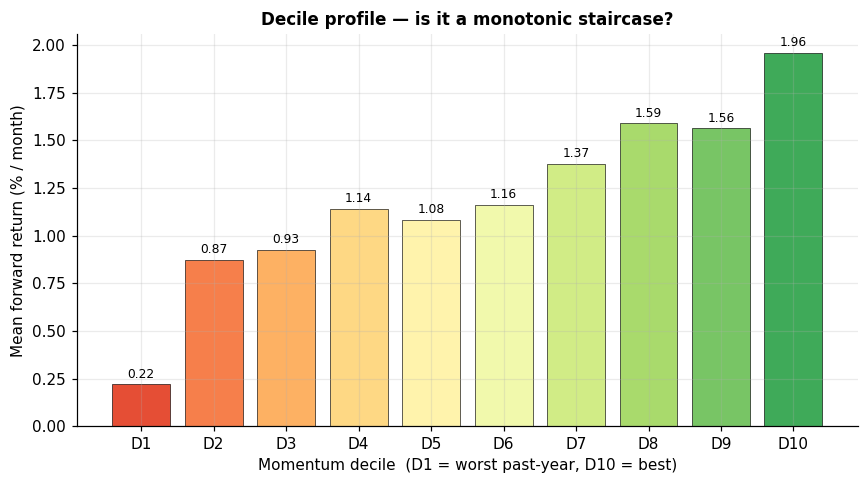

    -> plot: cumulative_spread_2026-07-27.png


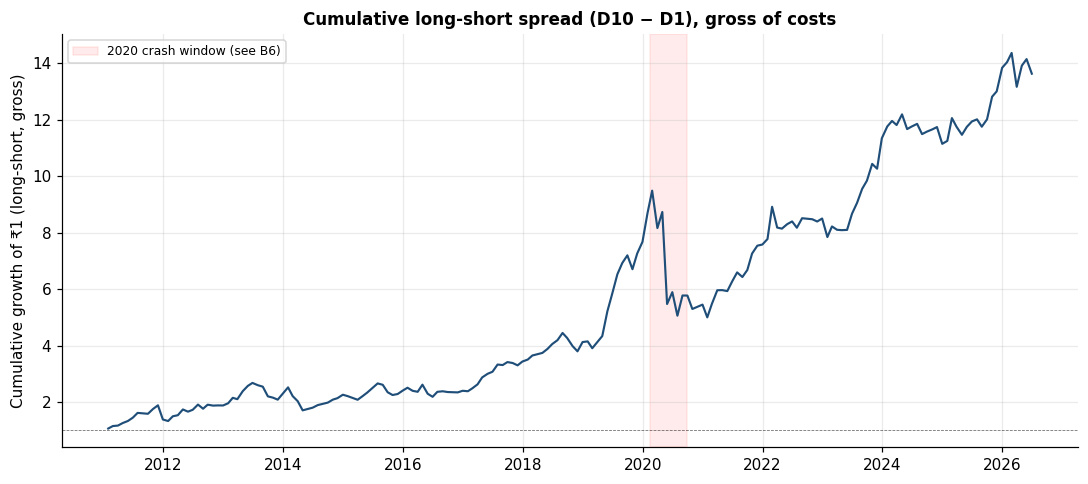

    -> artifact: long_short_spread_2026-07-27.csv  (179 rows)

  NOTE: all returns here are GROSS of transaction costs. Monthly
  rebalancing of a decile long-short has real turnover; costs are a
  documented baseline limitation, not modelled (that is an enhancement).


In [8]:
# =============================================================================
# CELL B3 — LONG-SHORT SPREAD + DECILE BAR CHART
# =============================================================================
# The strategy in one line: long decile 10 (best past-year), short decile 1
# (worst), equal-weighted, rebalanced monthly. The spread is D10 - D1 each
# month. Also plots the full decile profile, where MONOTONICITY is visible in a
# way the spread number alone is not.
# =============================================================================

spread = (decile_monthly["D10"] - decile_monthly["D1"]).rename("spread").to_frame()
spread["year"] = spread.index.year
spread_series = spread["spread"].dropna()

print(f"  Spread series: {len(spread_series)} monthly observations")
print(f"  Mean spread   : {spread_series.mean()*100:.4f}% / month")
print(f"  Std spread    : {spread_series.std(ddof=1)*100:.4f}% / month")
print(f"  Positive months: {(spread_series>0).mean()*100:.1f}%")
print(f"  Best / worst  : {spread_series.max()*100:.2f}% / {spread_series.min()*100:.2f}%")

# --- Plot 1: decile profile (the monotonicity chart) ------------------------
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = plt.cm.RdYlGn(np.linspace(0.15, 0.85, N_DECILES))
bars = ax.bar([f"D{i}" for i in range(1, 11)], decile_mean.values, color=colors,
              edgecolor="black", linewidth=0.4)
ax.axhline(0, color="black", linewidth=0.6)
ax.set_ylabel("Mean forward return (% / month)")
ax.set_xlabel("Momentum decile  (D1 = worst past-year, D10 = best)")
ax.set_title("Decile profile — is it a monotonic staircase?", fontsize=11, weight="bold")
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
for b, v in zip(bars, decile_mean.values):
    ax.text(b.get_x()+b.get_width()/2, v + (0.02 if v>=0 else -0.05),
            f"{v:.2f}", ha="center", va="bottom" if v>=0 else "top", fontsize=8)
save_plot(fig, "decile_profile")
plt.show()

# --- Plot 2: cumulative spread — the single most informative plot -----------
# Steady climb = persistent effect. Flat with one cliff = a single event.
cum = (1 + spread_series).cumprod()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(cum.index, cum.values, color="#1f4e79", linewidth=1.4)
ax.axhline(1, color="black", linewidth=0.5, linestyle="--", alpha=0.6)
ax.set_ylabel("Cumulative growth of ₹1 (long-short, gross)")
ax.set_title("Cumulative long-short spread (D10 − D1), gross of costs",
             fontsize=11, weight="bold")
# Shade the 2020 momentum-crash window for context (examined in B6).
ax.axvspan(pd.Timestamp("2020-02-15"), pd.Timestamp("2020-09-30"),
           color="red", alpha=0.08, label="2020 crash window (see B6)")
ax.legend(loc="upper left", fontsize=8)
save_plot(fig, "cumulative_spread")
plt.show()

save_artifact(spread.reset_index().rename(columns={"index":"rebalance_date"}),
              "long_short_spread")
print("\n  NOTE: all returns here are GROSS of transaction costs. Monthly")
print("  rebalancing of a decile long-short has real turnover; costs are a")
print("  documented baseline limitation, not modelled (that is an enhancement).")

## B4 — Real or luck? Block-bootstrap CI

Sharpe judges return *relative to noise*. The **block** bootstrap resamples 12-month chunks, preserving the autocorrelation in momentum returns — an iid bootstrap would give a falsely narrow CI. A result without a CI is not finished. Sharpe > 1.5 triggers a suspicion flag, not celebration.

FULL-SAMPLE PERFORMANCE (gross, equal-weighted, D10−D1)
  months                 : 179
  mean spread            : 1.7398% / month
     95% block-boot CI   : [0.7693%, 2.7054%]
  annualised return      : 19.14%
  annualised volatility  : 24.66%
  annualised SHARPE      : 0.847
     95% block-boot CI   : [0.335, 1.503]
     P(Sharpe > 0)       : 1.000
  hit rate               : 64.8% of months positive

  block length 12mo, 10,000 resamples, seed 20260724
    -> plot: bootstrap_sharpe_2026-07-27.png


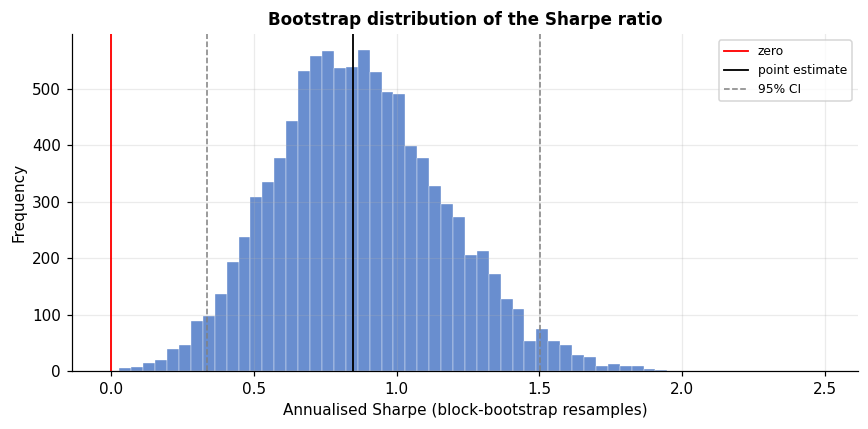

    -> artifact: bootstrap_draws_2026-07-27.csv  (10,000 rows)


In [9]:
# =============================================================================
# CELL B4 — FULL-SAMPLE STATISTICS WITH BLOCK-BOOTSTRAP CONFIDENCE INTERVALS
# =============================================================================
# Point estimates: annualised Sharpe, mean monthly spread, hit rate.
# CIs: BLOCK bootstrap (fact — momentum returns autocorrelate; an iid bootstrap
# resamples single months, destroys the clustering, and produces a CI that is
# too NARROW — overstating confidence). Block bootstrap resamples contiguous
# BLOCK_LEN-month chunks, preserving the runs, giving an honest interval.
#
# A result without a CI is not a finished result.
# =============================================================================

rng = np.random.default_rng(SEED)
x = spread_series.to_numpy()
n = len(x)

def ann_sharpe(a):
    m, s = a.mean(), a.std(ddof=1)
    return (m / s) * np.sqrt(12) if s > 0 else np.nan

point = {
    "mean_monthly_pct": x.mean() * 100,
    "ann_return_pct": ((1 + x).prod() ** (12 / n) - 1) * 100,
    "ann_vol_pct": x.std(ddof=1) * np.sqrt(12) * 100,
    "ann_sharpe": ann_sharpe(x),
    "hit_rate_pct": (x > 0).mean() * 100,
}

# --- Block bootstrap --------------------------------------------------------
# Draw ceil(n / BLOCK_LEN) blocks of BLOCK_LEN consecutive months (circular, so
# every start index is usable), concatenate, trim to n, recompute the metric.
n_blocks = int(np.ceil(n / BLOCK_LEN))
boot_sharpe = np.empty(N_BOOTSTRAP)
boot_mean = np.empty(N_BOOTSTRAP)
x_circ = np.concatenate([x, x[:BLOCK_LEN]])   # wrap for circular blocks
for b in range(N_BOOTSTRAP):
    starts = rng.integers(0, n, size=n_blocks)
    sample = np.concatenate([x_circ[s:s+BLOCK_LEN] for s in starts])[:n]
    boot_sharpe[b] = ann_sharpe(sample)
    boot_mean[b] = sample.mean() * 100

def ci(arr, lo=2.5, hi=97.5):
    return np.nanpercentile(arr, lo), np.nanpercentile(arr, hi)

sharpe_lo, sharpe_hi = ci(boot_sharpe)
mean_lo, mean_hi = ci(boot_mean)
p_sharpe_gt0 = float((boot_sharpe > 0).mean())

print("=" * 78)
print("FULL-SAMPLE PERFORMANCE (gross, equal-weighted, D10−D1)")
print("=" * 78)
print(f"  months                 : {n}")
print(f"  mean spread            : {point['mean_monthly_pct']:.4f}% / month")
print(f"     95% block-boot CI   : [{mean_lo:.4f}%, {mean_hi:.4f}%]")
print(f"  annualised return      : {point['ann_return_pct']:.2f}%")
print(f"  annualised volatility  : {point['ann_vol_pct']:.2f}%")
print(f"  annualised SHARPE      : {point['ann_sharpe']:.3f}")
print(f"     95% block-boot CI   : [{sharpe_lo:.3f}, {sharpe_hi:.3f}]")
print(f"     P(Sharpe > 0)       : {p_sharpe_gt0:.3f}")
print(f"  hit rate               : {point['hit_rate_pct']:.1f}% of months positive")
print(f"\n  block length {BLOCK_LEN}mo, {N_BOOTSTRAP:,} resamples, seed {SEED}")

# --- Suspicion trip-wire, stated in advance ---------------------------------
if point["ann_sharpe"] > 1.5:
    print("\n  ** Sharpe > 1.5 for a naive long-short with no risk management is")
    print("     SUSPICIOUS, not impressive. Prompt a leakage/survivorship hunt")
    print("     before treating this as a result. **")

# --- Plot: bootstrap Sharpe distribution ------------------------------------
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(boot_sharpe, bins=60, color="#4472c4", alpha=0.8, edgecolor="white", linewidth=0.3)
ax.axvline(0, color="red", linewidth=1.2, label="zero")
ax.axvline(point["ann_sharpe"], color="black", linewidth=1.2, label="point estimate")
ax.axvline(sharpe_lo, color="grey", linestyle="--", linewidth=1, label="95% CI")
ax.axvline(sharpe_hi, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Annualised Sharpe (block-bootstrap resamples)")
ax.set_ylabel("Frequency")
ax.set_title("Bootstrap distribution of the Sharpe ratio", fontsize=11, weight="bold")
ax.legend(fontsize=8)
save_plot(fig, "bootstrap_sharpe")
plt.show()

boot_df = pd.DataFrame({"boot_sharpe": boot_sharpe, "boot_mean_pct": boot_mean})
save_artifact(boot_df, "bootstrap_draws")
FULL_SAMPLE_STATS = {**point, "sharpe_ci_lo": sharpe_lo, "sharpe_ci_hi": sharpe_hi,
                     "mean_ci_lo": mean_lo, "mean_ci_hi": mean_hi,
                     "p_sharpe_gt0": p_sharpe_gt0}

## B5 — Year-by-year + rolling Sharpe · B6 — 2020 crash

Yearly figures are noisy (12 obs); the rolling Sharpe and cumulative curve are the trustworthy persistence views. 2020 is a pipeline check — **absence** of a momentum-crash drawdown would be the red flag.

  SPREAD BY YEAR (12 obs each — treat individual years as noisy):
    year   months   mean %/mo   sharpe    hit%
    2011       11      3.575%     1.15     82%
    2012       12      2.811%     1.38     58%
    2013       12      1.997%     0.90     50%
    2014       11      0.149%     0.06     73%
    2015       11      0.735%     0.43     55%
    2016       11      0.156%     0.09     45%
    2017       12      3.098%     2.89     67%
    2018       11      1.788%     1.28     73%
    2019       11      6.086%     2.63     82%
    2020       11     -1.782%    -0.40     55%
    2021       12      2.915%     1.91     75%
    2022       12      1.084%     0.71     50%
    2023       12      2.544%     1.79     67%
    2024       12     -0.112%    -0.14     67%
    2025       12      1.874%     1.89     75%
    2026        6     -0.147%    -0.10     67%
    -> plot: rolling_sharpe_2026-07-27.png


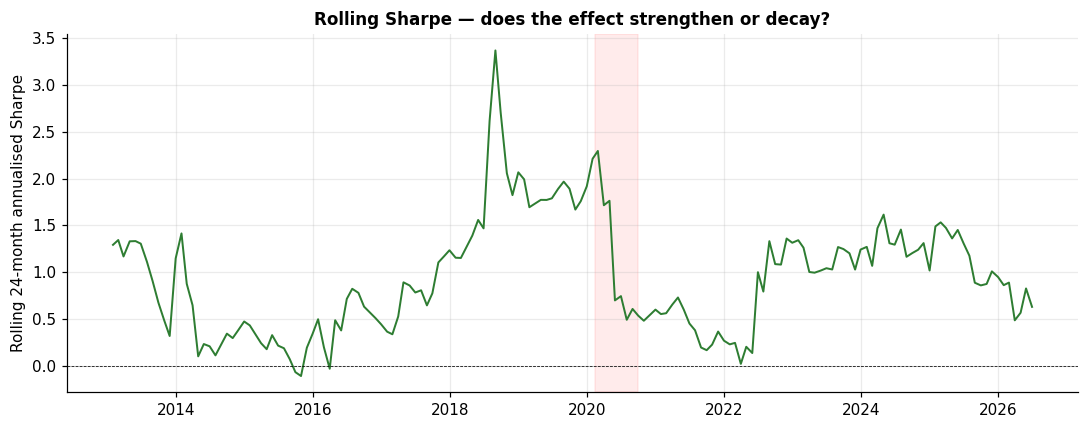

    -> artifact: spread_by_year_2026-07-27.csv  (16 rows)

2020 MOMENTUM-CRASH WINDOW (reported separately, not buried)
    month         spread %
    2020-01-31      13.36%
    2020-02-28       9.06%
    2020-03-31     -13.97%
    2020-04-30       6.98%
    2020-05-29     -37.34%
    2020-06-30       7.66%
    2020-07-31     -14.14%
    2020-08-31      14.14%
    2020-09-30      -0.04%

  Cumulative Jan–Sep 2020 spread: -24.80%
  Max drawdown within window   : -46.69%
  Verdict: drawdown PRESENT — consistent with the known momentum crash (reassuring for the pipeline)


In [10]:
# =============================================================================
# CELL B5 — YEAR BY YEAR + ROLLING SHARPE
# =============================================================================
# Persistence check. STRONG CAVEAT: 12 monthly observations per year gives an
# enormous standard error, so year-to-year differences are mostly NOISE. The
# yearly table is shown because it was asked for; the cumulative curve (B3) and
# rolling Sharpe (below) are the trustworthy views of persistence.
# =============================================================================

by_year = []
for yr, g in spread_series.groupby(spread_series.index.year):
    a = g.to_numpy()
    if len(a) < 2:
        continue
    by_year.append({
        "year": yr, "months": len(a),
        "mean_pct": a.mean()*100,
        "ann_sharpe": (a.mean()/a.std(ddof=1))*np.sqrt(12) if a.std(ddof=1)>0 else np.nan,
        "hit_pct": (a>0).mean()*100,
    })
year_tbl = pd.DataFrame(by_year)
print("  SPREAD BY YEAR (12 obs each — treat individual years as noisy):")
print(f"    {'year':<6}{'months':>7}{'mean %/mo':>12}{'sharpe':>9}{'hit%':>8}")
for _, r in year_tbl.iterrows():
    print(f"    {int(r['year']):<6}{int(r['months']):>7}{r['mean_pct']:>11.3f}%"
          f"{r['ann_sharpe']:>9.2f}{r['hit_pct']:>7.0f}%")

# Rolling 24-month Sharpe — persistence without the noise of single years.
roll = spread_series.rolling(24)
roll_sharpe = (roll.mean() / roll.std(ddof=1)) * np.sqrt(12)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(roll_sharpe.index, roll_sharpe.values, color="#2e7d32", linewidth=1.3)
ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
ax.set_ylabel("Rolling 24-month annualised Sharpe")
ax.set_title("Rolling Sharpe — does the effect strengthen or decay?",
             fontsize=11, weight="bold")
ax.axvspan(pd.Timestamp("2020-02-15"), pd.Timestamp("2020-09-30"),
           color="red", alpha=0.08)
save_plot(fig, "rolling_sharpe")
plt.show()
save_artifact(year_tbl, "spread_by_year")


# =============================================================================
# CELL B6 — 2020 MOMENTUM-CRASH CHECK
# =============================================================================
# Momentum crashes in sharp reversals: when the market bottoms and rebounds, the
# beaten-down losers (short leg) rebound hardest, hurting a long-winner/
# short-loser book. Mar–Sep 2020 was such a reversal. This is a PIPELINE CHECK:
# ABSENCE of a 2020 drawdown would make the pipeline suspect, not the strategy
# impressive.
# =============================================================================
print("\n" + "=" * 78)
print("2020 MOMENTUM-CRASH WINDOW (reported separately, not buried)")
print("=" * 78)
w2020 = spread_series[(spread_series.index >= "2020-01-01") &
                      (spread_series.index <= "2020-09-30")]
print(f"    {'month':<12}{'spread %':>10}")
for d, v in w2020.items():
    print(f"    {d.date().isoformat():<12}{v*100:>9.2f}%")
if len(w2020):
    cum2020 = (1 + w2020).prod() - 1
    print(f"\n  Cumulative Jan–Sep 2020 spread: {cum2020*100:.2f}%")
    trough = (1 + w2020).cumprod()
    dd = (trough / trough.cummax() - 1).min()
    print(f"  Max drawdown within window   : {dd*100:.2f}%")
    verdict = ("drawdown PRESENT — consistent with the known momentum crash "
               "(reassuring for the pipeline)") if dd < -0.05 else \
              ("NO clear drawdown — INVESTIGATE: forward returns or universe "
               "filter may be misbehaving")
    print(f"  Verdict: {verdict}")

## B7 — Liquidity trip-wire · B8 — 2018 check · B9 — Information coefficient

**B7 is the most important cell.** If the spread lives only in the illiquid tercile, the strategy is a paper mirage — that is the headline. B8 flags the known 2018 H2 membership artifact. B9's IC uses the whole cross-section, a more efficient cross-check on the extreme-decile spread.

  D10−D1 spread WITHIN each liquidity tercile:
    T1 illiquid    mean=  1.966%/mo  sharpe= 0.88  n=179
    T2 middle      mean=  2.127%/mo  sharpe= 0.95  n=179
    T3 liquid      mean=  1.032%/mo  sharpe= 0.42  n=179

  READ THIS CAREFULLY:
    If the spread is strong in T1 and weak/absent in T3, the effect is
    real but NOT tradeable at size — the headline, not a footnote.
    If it survives in T3 (liquid), it is a genuine tradeable effect.
    -> plot: spread_by_liquidity_tercile_2026-07-27.png


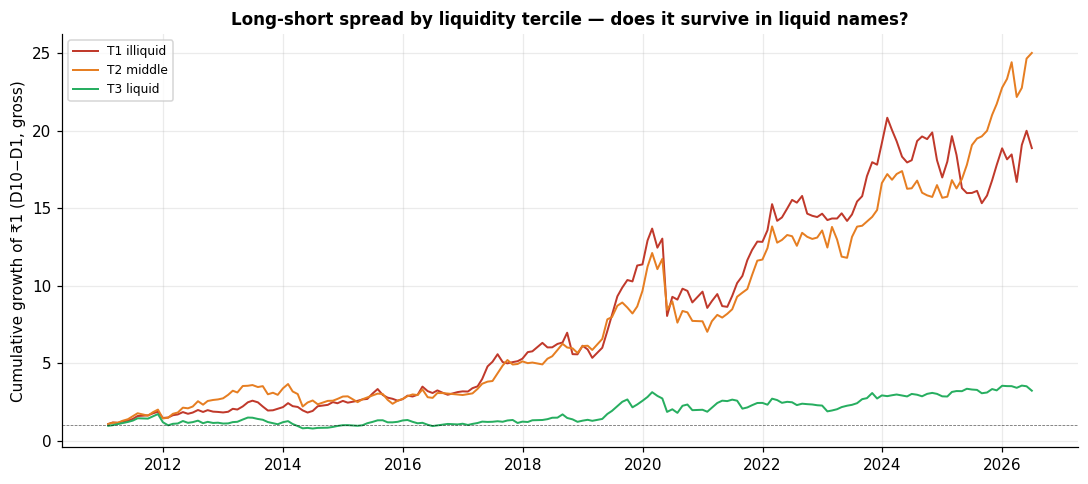

    -> artifact: spread_tercile_1_2026-07-27.csv  (179 rows)
    -> artifact: spread_tercile_2_2026-07-27.csv  (179 rows)
    -> artifact: spread_tercile_3_2026-07-27.csv  (179 rows)

2018 H2 CHECK (known ~22% membership-misclassification window)
  2018 H2 mean spread : 0.462%/mo  (n=6)
  rest of sample      : 1.784%/mo  (n=173)
  crude z vs rest     : 0.45
  If 2018 H2 is a large outlier, attribute to the membership artifact
  FIRST — do not report it as a momentum finding.

INFORMATION COEFFICIENT (Spearman rank corr, full cross-section)
  months            : 179
  mean IC           : 0.0605
     95% block CI   : [0.0350, 0.0865]
  IC std            : 0.1744
  IC info ratio     : 0.347   (mean/std, annualised ×√12 = 1.20)
  positive-IC months: 66.5%
    -> plot: information_coefficient_2026-07-27.png


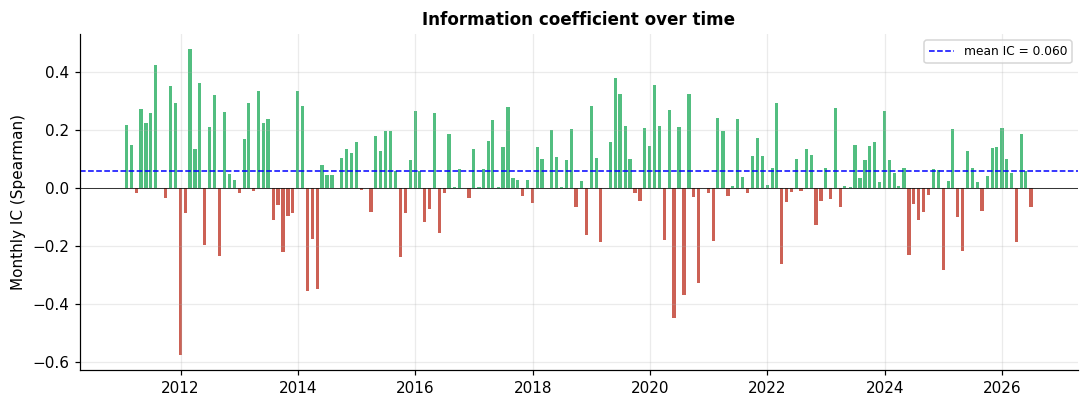

    -> artifact: information_coefficient_2026-07-27.csv  (179 rows)


In [11]:
# =============================================================================
# CELL B7 — LIQUIDITY TERCILE DECOMPOSITION  [THE TRIP-WIRE]
# =============================================================================
# Most published anomalies are real but live entirely in illiquid names you
# cannot trade at size. Split the universe into thirds by trailing turnover and
# compute the D10−D1 spread WITHIN each third. If the spread lives only in the
# illiquid tercile, the strategy is a paper mirage — and THAT is the headline.
#
# Terciles use trailing-mean turnover over [t-21, t-1] (rebalance day excluded,
# no leakage), assigned cross-sectionally within each month's eligible set.
# =============================================================================

tturn = {}
for tkr, grp in panel.groupby(TICKER_COL, sort=False):
    tturn[tkr] = grp["turnover"].to_numpy(dtype=float)

def trailing_turnover(tkr, rb, window=21, min_valid=15):
    td = tdata[tkr]
    p = find_pos(td["dates"], rb)
    if p is None or p - window < 0:
        return np.nan
    vals = tturn[tkr][p-window:p]   # [t-21, t-1], excludes rebalance day
    if int(np.sum(~np.isnan(vals))) < min_valid:
        return np.nan
    return float(np.nanmean(vals))

# Attach turnover + tercile to the forward-return frame.
fwd_ok = fwd_ok.copy()
fwd_ok["trail_turnover"] = [
    trailing_turnover(t, pd.Timestamp(rb))
    for t, rb in zip(fwd_ok[TICKER_COL], fwd_ok["rebalance_date"])]

# Assign in place via .groups indexing — groupby().apply() can consume the
# grouping column (fact #28), which cost us the same KeyError twice before.
fwd_ok["liq_tercile"] = np.nan
for _rb, _idx in fwd_ok.groupby("rebalance_date").groups.items():
    _sub = fwd_ok.loc[_idx]
    _vidx = _sub.index[_sub["trail_turnover"].notna()]
    if len(_vidx) >= N_TERCILES:
        _r = fwd_ok.loc[_vidx, "trail_turnover"].rank(method="first")
        fwd_ok.loc[_vidx, "liq_tercile"] = np.ceil(N_TERCILES * _r / len(_vidx)).clip(1, N_TERCILES)

# Spread within each tercile: mean D10 and D1 forward return per month, by tercile.
print("  D10−D1 spread WITHIN each liquidity tercile:")
tercile_spreads = {}
for t in (1, 2, 3):
    sub = fwd_ok[fwd_ok["liq_tercile"] == t]
    dm = sub.groupby(["rebalance_date","decile"])["fwd_return"].mean().unstack("decile")
    if 10 in dm.columns and 1 in dm.columns:
        sp = (dm[10] - dm[1]).dropna()
        tercile_spreads[t] = sp
        shp = (sp.mean()/sp.std(ddof=1))*np.sqrt(12) if sp.std(ddof=1)>0 else np.nan
        label = {1:"T1 illiquid",2:"T2 middle",3:"T3 liquid"}[t]
        print(f"    {label:<14} mean={sp.mean()*100:>7.3f}%/mo  sharpe={shp:>5.2f}  "
              f"n={len(sp)}")

print("\n  READ THIS CAREFULLY:")
print("    If the spread is strong in T1 and weak/absent in T3, the effect is")
print("    real but NOT tradeable at size — the headline, not a footnote.")
print("    If it survives in T3 (liquid), it is a genuine tradeable effect.")

# Plot: three cumulative curves overlaid.
fig, ax = plt.subplots(figsize=(10, 4.5))
cols = {1:"#c0392b", 2:"#e67e22", 3:"#27ae60"}
lbls = {1:"T1 illiquid", 2:"T2 middle", 3:"T3 liquid"}
for t, sp in tercile_spreads.items():
    ax.plot(sp.index, (1+sp).cumprod().values, color=cols[t], linewidth=1.3, label=lbls[t])
ax.axhline(1, color="black", linewidth=0.5, linestyle="--", alpha=0.6)
ax.set_ylabel("Cumulative growth of ₹1 (D10−D1, gross)")
ax.set_title("Long-short spread by liquidity tercile — does it survive in liquid names?",
             fontsize=11, weight="bold")
ax.legend(fontsize=8)
save_plot(fig, "spread_by_liquidity_tercile")
plt.show()

for t, sp in tercile_spreads.items():
    save_artifact(sp.reset_index().rename(columns={0:"spread","index":"rebalance_date"}),
                  f"spread_tercile_{t}")


# =============================================================================
# CELL B8 — 2018 H2 CHECK
# =============================================================================
# 2018-07-01 → 2018-12-30 membership is carried forward from a corrupted
# snapshot (up to ~22% misclassification). Flag any anomaly there as a likely
# DATA explanation BEFORE any interpretation as a finding.
# =============================================================================
print("\n" + "=" * 78)
print("2018 H2 CHECK (known ~22% membership-misclassification window)")
print("=" * 78)
h2 = spread_series[(spread_series.index >= "2018-07-01") &
                   (spread_series.index <= "2018-12-31")]
rest = spread_series[~spread_series.index.isin(h2.index)]
print(f"  2018 H2 mean spread : {h2.mean()*100:.3f}%/mo  (n={len(h2)})")
print(f"  rest of sample      : {rest.mean()*100:.3f}%/mo  (n={len(rest)})")
z = abs(h2.mean() - rest.mean()) / (rest.std(ddof=1)/np.sqrt(max(len(h2),1)))
print(f"  crude z vs rest     : {z:.2f}")
print("  If 2018 H2 is a large outlier, attribute to the membership artifact")
print("  FIRST — do not report it as a momentum finding.")


# =============================================================================
# CELL B9 — INFORMATION COEFFICIENT
# =============================================================================
# The decile spread uses only the top and bottom 10%. The IC uses the WHOLE
# cross-section each month: the rank correlation (Spearman) between momentum
# signal and forward return across ALL eligible names. More efficient, more
# stable, and a genuine cross-check — a positive stable IC with a noisy spread
# means the signal works but the extremes are noisy.
# =============================================================================
print("\n" + "=" * 78)
print("INFORMATION COEFFICIENT (Spearman rank corr, full cross-section)")
print("=" * 78)
ic_rows = []
for rb, g in fwd_ok.groupby("rebalance_date"):
    gg = g[["signal","fwd_return"]].dropna()
    if len(gg) >= MIN_NAMES_PER_MONTH:
        ic = gg["signal"].rank().corr(gg["fwd_return"].rank())  # Spearman via ranks
        ic_rows.append({"rebalance_date": rb, "ic": ic, "n": len(gg)})
ic_df = pd.DataFrame(ic_rows)
ic = ic_df["ic"].to_numpy()

# Block-bootstrap CI on mean IC (same autocorrelation concern as the spread).
n_ic = len(ic); ic_circ = np.concatenate([ic, ic[:BLOCK_LEN]])
nb = int(np.ceil(n_ic/BLOCK_LEN))
boot_ic = np.empty(N_BOOTSTRAP)
for b in range(N_BOOTSTRAP):
    s = rng.integers(0, n_ic, size=nb)
    boot_ic[b] = np.concatenate([ic_circ[i:i+BLOCK_LEN] for i in s])[:n_ic].mean()
ic_lo, ic_hi = np.percentile(boot_ic, [2.5, 97.5])
ic_ir = ic.mean()/ic.std(ddof=1) if ic.std(ddof=1)>0 else np.nan

print(f"  months            : {n_ic}")
print(f"  mean IC           : {ic.mean():.4f}")
print(f"     95% block CI   : [{ic_lo:.4f}, {ic_hi:.4f}]")
print(f"  IC std            : {ic.std(ddof=1):.4f}")
print(f"  IC info ratio     : {ic_ir:.3f}   (mean/std, annualised ×√12 = {ic_ir*np.sqrt(12):.2f})")
print(f"  positive-IC months: {(ic>0).mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(ic_df["rebalance_date"], ic_df["ic"], width=20,
       color=np.where(ic_df["ic"]>=0, "#27ae60", "#c0392b"), alpha=0.8)
ax.axhline(0, color="black", linewidth=0.5)
ax.axhline(ic.mean(), color="blue", linewidth=1, linestyle="--",
           label=f"mean IC = {ic.mean():.3f}")
ax.set_ylabel("Monthly IC (Spearman)")
ax.set_title("Information coefficient over time", fontsize=11, weight="bold")
ax.legend(fontsize=8)
save_plot(fig, "information_coefficient")
plt.show()
save_artifact(ic_df, "information_coefficient")

IC_STATS = {"mean_ic": ic.mean(), "ic_ci_lo": ic_lo, "ic_ci_hi": ic_hi,
            "ic_ir": ic_ir, "pos_ic_pct": (ic>0).mean()*100}

In [12]:
# =============================================================================
# REVIEW SUMMARY — single structured block for external review
# Reads existing variables only; recomputes nothing.
# =============================================================================
L = []; A = L.append

A("="*70); A("PHASE B MOMENTUM — REVIEW SUMMARY"); A("="*70)

# --- SAMPLE ACCOUNTING (the 179-vs-199 question) --------------------------
A("\n[1] SAMPLE ACCOUNTING")
A(f"  usable rebalances (Phase A calendar) : {len(REBAL_USABLE)}")
A(f"  rebalances with full decile set      : {valid['rebalance_date'].nunique()}")
A(f"  months skipped (<{MIN_NAMES_PER_MONTH} names)          : {len(skipped_months)}")
if skipped_months:
    A(f"    skipped dates: {[str(pd.Timestamp(d).date()) for d in skipped_months]}")
A(f"  spread series length (B3)            : {len(spread_series)}")
# reconcile: usable - skipped - (rebalances with no forward return computed)
_have_fwd = decile_monthly.shape[0]
A(f"  decile_monthly rows (B2)             : {_have_fwd}")
A(f"  first / last spread month            : {spread_series.index.min().date()} / {spread_series.index.max().date()}")
# where did the early months go? show eligible-name count for the first 18 rebalances
A("\n  Eligible-name count, first 18 usable rebalances (warm-up visibility):")
_first = valid.groupby("rebalance_date")["n_names"].first().sort_index().head(18)
for d, n in _first.items():
    A(f"    {pd.Timestamp(d).date()}  n={int(n)}")

# --- FULL-SAMPLE STATS (exact figures for the log) ------------------------
A("\n[2] FULL-SAMPLE STATS (exact)")
s = FULL_SAMPLE_STATS
A(f"  n months            : {len(spread_series)}")
A(f"  mean spread %/mo     : {s['mean_monthly_pct']:.4f}   CI[{s['mean_ci_lo']:.4f}, {s['mean_ci_hi']:.4f}]")
A(f"  annualised return %  : {s['ann_return_pct']:.3f}")
A(f"  annualised vol %     : {s['ann_vol_pct']:.3f}")
A(f"  annualised Sharpe    : {s['ann_sharpe']:.4f}   CI[{s['sharpe_ci_lo']:.4f}, {s['sharpe_ci_hi']:.4f}]")
A(f"  P(Sharpe>0)          : {s['p_sharpe_gt0']:.4f}")
A(f"  hit rate %           : {s['hit_rate_pct']:.2f}")

# --- DECILE PROFILE + MONOTONICITY ----------------------------------------
A("\n[3] DECILE PROFILE (%/mo, equal-weighted)")
for c in decile_monthly.columns:
    A(f"    {c:<5} {decile_mean[c]:>8.4f}")
_mono = sum(decile_mean[f"D{i+1}"] > decile_mean[f"D{i}"] for i in range(1, N_DECILES))
A(f"  monotonic steps: {_mono}/9")

# --- TERMINATIONS ---------------------------------------------------------
A("\n[4] TERMINATIONS (B2)")
A(f"  terminated mid-month positions : {n_term}")
A(f"  positions with no fwd return   : {len(gone)}")
if n_term:
    _td = term.groupby('decile').size().reindex(range(1,11), fill_value=0)
    A(f"  by decile: {dict(_td)}")

# --- TERCILE + IC + 2018 (echo, for one-shot completeness) ----------------
A("\n[5] TERCILE / IC / 2018 (echo)")
for t, sp in tercile_spreads.items():
    shp = (sp.mean()/sp.std(ddof=1))*np.sqrt(12)
    A(f"  T{t} {'illiq mid liq'.split()[t-1]:<5} mean={sp.mean()*100:.3f}%/mo sharpe={shp:.3f} n={len(sp)}")
A(f"  mean IC {IC_STATS['mean_ic']:.4f} CI[{IC_STATS['ic_ci_lo']:.4f},{IC_STATS['ic_ci_hi']:.4f}] "
  f"IR={IC_STATS['ic_ir']:.3f} pos={IC_STATS['pos_ic_pct']:.1f}%")

print("\n".join(L))

PHASE B MOMENTUM — REVIEW SUMMARY

[1] SAMPLE ACCOUNTING
  usable rebalances (Phase A calendar) : 198
  rebalances with full decile set      : 179
  months skipped (<100 names)          : 19
    skipped dates: ['2010-01-29', '2010-02-26', '2010-03-31', '2010-04-30', '2010-05-31', '2010-06-30', '2010-07-30', '2010-08-31', '2010-09-30', '2010-10-29', '2010-11-30', '2010-12-31', '2011-08-31', '2014-08-29', '2015-02-28', '2016-10-31', '2018-03-29', '2019-03-29', '2020-11-30']
  spread series length (B3)            : 179
  decile_monthly rows (B2)             : 179
  first / last spread month            : 2011-01-31 / 2026-06-30

  Eligible-name count, first 18 usable rebalances (warm-up visibility):
    2011-01-31  n=473
    2011-02-28  n=483
    2011-03-31  n=480
    2011-04-29  n=479
    2011-05-31  n=479
    2011-06-30  n=473
    2011-07-29  n=472
    2011-09-30  n=449
    2011-10-31  n=451
    2011-11-30  n=451
    2011-12-30  n=450
    2012-01-31  n=451
    2012-02-29  n=449
    2012-

## B10 — Findings log

Written in your schema. `decision`, `insight`, and `incidental_observations` are left for **you** to fill — those are judgments the code should not fabricate.

In [13]:
# =============================================================================
# CELL B10 — FINDINGS LOG (written to momentum/ root when the test completes)
# =============================================================================
# Written in the Scout/Implementer schema. The machine artifacts under
# run_<date>/ are the evidence; this log is the human-readable conclusion. Kept
# distinct so a summary can never silently drift from what the code produced.
# =============================================================================

_sh = FULL_SAMPLE_STATS
_mono = sum(decile_mean[f"D{i+1}"] > decile_mean[f"D{i}"] for i in range(1, N_DECILES))

# Assemble the tercile summary line.
_terc = "; ".join(
    f"{ {1:'T1illiq',2:'T2mid',3:'T3liq'}[t] }={sp.mean()*100:.2f}%/mo"
    for t, sp in tercile_spreads.items())

_dd2020 = ""
if len(w2020):
    _tr = (1 + w2020).cumprod()
    _dd2020 = f"{(_tr/_tr.cummax()-1).min()*100:.1f}%"

log = f"""# Momentum — Test 1 findings

id: momentum_12_1_decile_ls
date: {RUN_DATE}
hypothesis: Cross-sectional 12-1 momentum — high trailing-return stocks outperform low over the next month (harness-validation test)
category: momentum
mechanism_tags: cross_sectional, price_momentum, decile_long_short, equal_weighted

data_and_universe: >
  Nifty 500 PIT universe, v3 panel (feature_panel_with_pit_v2 derived from
  raw_price_panel_consolidated_v3; 3,328,132 rows, 2010-01-04 to 2026-07-10).
  Signal = compounded daily_return over [t-252, t-21] (12-1 momentum). Monthly
  rebalance on the last trading day. PIT filter in_nifty500_flag == 1. Strict
  232/232 clean window, vendor-failure dates (2025-03-18) excluded from the
  requirement. Months with <{MIN_NAMES_PER_MONTH} eligible names skipped.
  IMPORTANT: the eligible universe is "Nifty 500 names with a clean trailing
  year", NOT the full Nifty 500 — in distress-heavy years the 232 filter
  removes many flagged-but-untradeable names (see 2024 finding in memory doc).

result: >
  Long-short D10-D1, equal-weighted, GROSS of costs. {len(spread_series)} monthly obs.
  Mean spread {_sh['mean_monthly_pct']:.3f}%/mo (95% block-boot CI
  [{_sh['mean_ci_lo']:.3f}%, {_sh['mean_ci_hi']:.3f}%]).
  Annualised Sharpe {_sh['ann_sharpe']:.3f} (95% CI
  [{_sh['sharpe_ci_lo']:.3f}, {_sh['sharpe_ci_hi']:.3f}], P(Sharpe>0)={_sh['p_sharpe_gt0']:.3f}).
  Hit rate {_sh['hit_rate_pct']:.1f}%. Decile monotonic steps {_mono}/9.
  Mean IC {IC_STATS['mean_ic']:.4f} (95% CI [{IC_STATS['ic_ci_lo']:.4f}, {IC_STATS['ic_ci_hi']:.4f}]),
  IC info ratio {IC_STATS['ic_ir']:.3f}.
  Liquidity terciles: {_terc}.
  2020 crash-window max drawdown: {_dd2020}.

validation_summary: >
  coverage: eligible universe ~430-490/mo normal years, {len(skipped_months)} months skipped (<{MIN_NAMES_PER_MONTH}).
  spot-check: leakage self-test passed (window strictly before rebalance, gap>=21d).
  leakage: 0 forward-looking violations by construction (forward window starts t+1).
  universe: PIT filter == 1 applied; RANBAXY/HDFC transitions correct (Phase A).

holdout_status: n/a (dev-period baseline; no holdout split defined for this harness test)
decision: [FILL IN after reading — expected: promoted/reject/needs modification]
insight: [FILL IN — one sentence, independent of pass/fail]

incidental_observations: >
  [REQUIRED — fill in from the run. Candidates to check: is the spread
  monotonic or driven by extremes? Does it concentrate in T1 (illiquid)? Any
  decade where it decays? Anything odd in the IC series? 2018 H2 outlier?]

flag_for_idea_generator: >
  [If any incidental seeds a new hypothesis, phrase it here as a gap/question.]

related_ids: [reversal (shares daily_return + PIT flag; opposite sign at short horizon)]
"""

log_path = HYP_ROOT / f"momentum_findings_{RUN_DATE}.md"
log_path.write_text(log)
print("=" * 78)
print("FINDINGS LOG (skeleton — decision/insight/incidental need YOUR input)")
print("=" * 78)
print(log)
print(f"\n  -> written: {log_path.relative_to(BASE)}")
print(f"  -> artifacts: {ARTIFACT_DIR.relative_to(BASE)}")
print(f"  -> plots: {PLOT_DIR.relative_to(BASE)}")
print("\n  Baseline complete. This run is FROZEN as the reference for any later")
print("  enhancement. Fill decision/insight/incidental_observations by hand —")
print("  those are judgments the code should not fabricate.")

FINDINGS LOG (skeleton — decision/insight/incidental need YOUR input)
# Momentum — Test 1 findings

id: momentum_12_1_decile_ls
date: 2026-07-27
hypothesis: Cross-sectional 12-1 momentum — high trailing-return stocks outperform low over the next month (harness-validation test)
category: momentum
mechanism_tags: cross_sectional, price_momentum, decile_long_short, equal_weighted

data_and_universe: >
  Nifty 500 PIT universe, v3 panel (feature_panel_with_pit_v2 derived from
  raw_price_panel_consolidated_v3; 3,328,132 rows, 2010-01-04 to 2026-07-10).
  Signal = compounded daily_return over [t-252, t-21] (12-1 momentum). Monthly
  rebalance on the last trading day. PIT filter in_nifty500_flag == 1. Strict
  232/232 clean window, vendor-failure dates (2025-03-18) excluded from the
  requirement. Months with <100 eligible names skipped.
  IMPORTANT: the eligible universe is "Nifty 500 names with a clean trailing
  year", NOT the full Nifty 500 — in distress-heavy years the 232 filter
  remo

In [14]:
# =============================================================================
# BASELINE CLOSEOUT — relabel `terminated` -> `incomplete_month`
# =============================================================================
# Run ONCE against the frozen baseline run folder. The B2 flag named
# `terminated` actually fires whenever a position traded FEWER days than the
# full market month — i.e. any ordinary no-trade day, not a delisting. Left
# as-is, "42,049 terminated" reads as 42,049 delistings, which is false and
# alarming. Genuine terminations are 37 (Phase A) / 9 with no forward return.
#
# This does NOT change any result — the flag is uniform across deciles and was
# never used in the spread/Sharpe/IC computation. It only corrects the column
# NAME and adds an honest genuine-termination marker, so the archived artifact
# does not mislead a future reader.
#
# Rewrites forward_returns_detail in place with the corrected schema, and writes
# a one-line note recording the relabel.
# =============================================================================
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/moonshot_compounding")
RUN_DATE = "2026-07-25"
art = BASE / "hypotheses" / "momentum" / f"run_{RUN_DATE}" / "artifacts"
fpath = art / f"forward_returns_detail_{RUN_DATE}.csv"

fr = pd.read_csv(fpath)
assert "terminated" in fr.columns, "already relabelled or wrong file"

# Rename the misleading column; add an explicit genuine-termination marker.
fr = fr.rename(columns={"terminated": "incomplete_month"})
# Genuine termination = held ZERO observable forward days (fwd_return is NaN).
fr["genuine_no_forward_return"] = fr["fwd_return"].isna()

n_incomplete = int(fr["incomplete_month"].sum())
n_genuine = int(fr["genuine_no_forward_return"].sum())

fr.to_csv(fpath, index=False)
note = art / f"RELABEL_NOTE_{RUN_DATE}.txt"
note.write_text(
    f"forward_returns_detail column 'terminated' renamed to 'incomplete_month'.\n"
    f"It means: position traded fewer days than the full market month (ordinary\n"
    f"no-trade days), NOT a delisting. Count = {n_incomplete:,}, uniform across\n"
    f"deciles, never used in any return computation.\n"
    f"Added 'genuine_no_forward_return' (fwd_return is NaN): count = {n_genuine}.\n"
    f"Phase A stricter true-termination count = 37, evenly spread across deciles.\n"
    f"Results (spread/Sharpe/IC/deciles) are UNCHANGED by this relabel.\n")

print(f"  relabelled: {fpath.name}")
print(f"  incomplete_month rows       : {n_incomplete:,}")
print(f"  genuine_no_forward_return   : {n_genuine}")
print(f"  note written: {note.name}")
print("\n  Baseline artifacts now honestly labelled. Result unchanged.")

  relabelled: forward_returns_detail_2026-07-25.csv
  incomplete_month rows       : 42,058
  genuine_no_forward_return   : 9
  note written: RELABEL_NOTE_2026-07-25.txt

  Baseline artifacts now honestly labelled. Result unchanged.


---

## After this run

1. Read the plots and the B4 / B7 / B9 numbers.
2. Fill `decision`, `insight`, `incidental_observations` in the findings log by hand.
3. This run is **frozen** as the baseline reference. Enhancements become new
   log entries measured against it.

**How to read the headline:** Sharpe with its CI (is the CI clear of zero?),
decile monotonicity (staircase or jumble?), and the tercile decomposition (does
it survive in liquid names?). A positive spread that lives only in T1, or a wide
spread with a jumbled middle, is *not* a clean pass however good the point
estimate looks.